# 연습 문제 2-1 ~ 2-3 풀이: 퍼셉트론, 가중합, 시그모이드, 결정 경계

2-1절 연습 문제 2-1 ~ 2-3의 풀이 예시다. 정답이 하나뿐인 문제가 아니므로 다른 방법으로도 구현할 수 있다.

- 본문 예제 코드는 `code_examples/ch02/` 아래 예제 노트북을 참고한다.

In [7]:
# torch 라이브러리 임포트
import torch

## 연습 문제 2-1

> [그림 2-2]의 퍼셉트론에서 가중치가 각각 0.5와 -0.5, 편향이 0.1일 때,
> 입력 (1, 0)과 (0, 1)에 대한 뉴런의 가중합 z를 계산해 보자.

**가중합 z 계산하기**
- 가중합: z = x1 * w1 + x2 * w2 + b
- 입력 (1, 0): z = 1 * 0.5 + 0 * (-0.5) + 0.1
- 입력 (0, 1): z = 0 * 0.5 + 1 * (-0.5) + 0.1
- 입력을 행으로 쌓은 (2, 2) 텐서와 가중치 (2, 1) 텐서를 행렬곱으로 한 번에 계산

In [8]:
weights = torch.tensor([[0.5], [-0.5]])    # (2, 1): 가중치 w1, w2
bias = torch.tensor([0.1])                 # 편향 b
X = torch.tensor([[1., 0.], [0., 1.]])     # (2, 2): 입력 (1, 0), (0, 1)

Z = X @ weights + bias                     # 가중합 z, (2, 1)
for x, z in zip(X.tolist(), Z.flatten().tolist()):
    print(f'입력 {tuple(x)}의 가중합 z: {z:.1f}')

입력 (1.0, 0.0)의 가중합 z: 0.6
입력 (0.0, 1.0)의 가중합 z: -0.4


**결과 설명**
- 입력 (1, 0)은 z = 0.6, 입력 (0, 1)은 z = -0.4
- 두 가중치의 부호가 달라서 z의 부호가 갈린다
- 첫 번째 입력은 z를 키우는 쪽으로, 두 번째 입력은 줄이는 쪽으로 작용

## 연습 문제 2-2

> [그림 2-2]의 퍼셉트론에서 시그모이드 활성화 함수를 거친 출력값 y의 값을 반환하는 파이썬 함수를 작성한 후,
> [연습문제 2-1]의 조건을 사용해 퍼셉트론의 출력값을 구해 보자.

**퍼셉트론 함수 만들기**
- 가중합 z를 구한 뒤 시그모이드 활성화 함수를 거친 출력 y를 반환
- 시그모이드 함수: 1 / (1 + exp(-z))
- 2-1의 가중치, 편향, 입력으로 출력 계산

In [9]:
def perceptron(X, weights, bias):
    Z = X @ weights + bias                  # 가중합
    return 1 / (1 + torch.exp(-Z))          # 시그모이드 활성화 함수

Y = perceptron(X, weights, bias)
for x, y in zip(X.tolist(), Y.flatten().tolist()):
    print(f'입력 {tuple(x)} -> 출력 y: {y:.4f}')
print(f'torch.sigmoid()와 같은가: {torch.allclose(Y, torch.sigmoid(X @ weights + bias))}')

입력 (1.0, 0.0) -> 출력 y: 0.6457
입력 (0.0, 1.0) -> 출력 y: 0.4013
torch.sigmoid()와 같은가: True


**결과 설명**
- z = 0.6은 y = 0.6457, z = -0.4는 y = 0.4013
- 시그모이드 함수는 z = 0에서 0.5를 지난다: z가 양수이면 y는 0.5보다 크고, 음수이면 작다
- z의 부호가 곧 0.5를 기준으로 한 분류 결과

## 연습 문제 2-3

> 퍼셉트론의 결정 경계는 가중치와 편향에 따라 달라진다.
> 다음 세 가지 경우에서 결정 경계의 기울기와 x2축 절편을 각각 구하고 결정 경계가 어떻게 달라지는지 설명해 보자.
>
> 1. w1=1, w2=1, b=0
> 2. w1=2, w2=1, b=0
> 3. w1=1, w2=1, b=1

**결정 경계의 식 구하기**
- 결정 경계는 z = 0인 점들의 모임: x1 * w1 + x2 * w2 + b = 0
- x2에 대해 정리: x2 = -(w1 / w2) * x1 - b / w2
- 기울기는 -w1 / w2, x2축 절편은 -b / w2

In [10]:
CASES = [(1., 1., 0.), (2., 1., 0.), (1., 1., 1.)]    # (w1, w2, b)

print(f'{"w1":>4} {"w2":>4} {"b":>4} | {"기울기"} {"x2축 절편"}')
for w1, w2, b in CASES:
    slope = -w1 / w2                       # 기울기 -w1/w2
    intercept = -b / w2 + 0.0              # x2축 절편 -b/w2 (+ 0.0은 -0.0 표시 방지)
    print(f'{w1:4.0f} {w2:4.0f} {b:4.0f} | {slope:6.1f} {intercept:9.1f}')

  w1   w2    b | 기울기 x2축 절편
   1    1    0 |   -1.0       0.0
   2    1    0 |   -2.0       0.0
   1    1    1 |   -1.0      -1.0


**구한 직선이 맞는지 z로 검산하기**
- 직선 위의 점이라면 가중합 z가 0이어야 한다
- 각 경우에서 x1 = 0, 2일 때 직선 위의 점을 찾아 z를 계산

In [11]:
for w1, w2, b in CASES:
    slope, intercept = -w1 / w2, -b / w2
    zs = [w1 * x1 + w2 * (slope * x1 + intercept) + b for x1 in (0., 2.)]
    print(f'w1={w1:.0f}, w2={w2:.0f}, b={b:.0f}: 직선 위 두 점의 z = {zs}')

w1=1, w2=1, b=0: 직선 위 두 점의 z = [0.0, 0.0]
w1=2, w2=1, b=0: 직선 위 두 점의 z = [0.0, 0.0]
w1=1, w2=1, b=1: 직선 위 두 점의 z = [0.0, 0.0]


**세 결정 경계를 좌표평면에 그려 보기**
- 세 경우의 직선을 한 좌표평면에 함께 그린다
- 점은 각 직선의 x2축 절편
- 시각화에는 matplotlib을 사용하며, 한글 폰트는 `code_reference`의 함수로 설정

In [12]:
# 시각화 준비: matplotlib과 한글 폰트 설정
import sys
import matplotlib.pyplot as plt

sys.path.append('../../')
from code_reference import common

common.set_korean_plot_env()

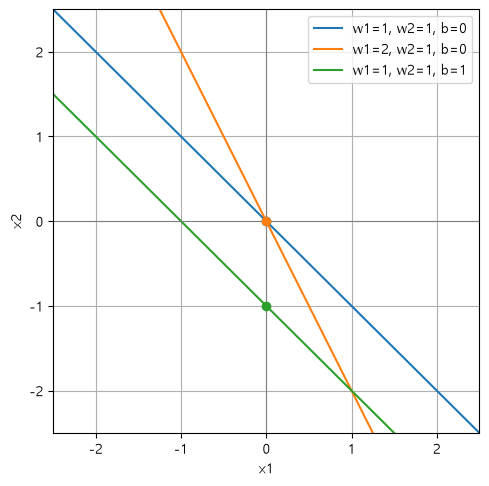

In [13]:
x1 = torch.linspace(-2.5, 2.5, 100)
plt.figure(figsize=(5.5, 5.5))
for w1, w2, b in CASES:
    x2 = -(w1 / w2) * x1 - b / w2                       # 결정 경계의 x2 값
    line, = plt.plot(x1, x2, label=f'w1={w1:.0f}, w2={w2:.0f}, b={b:.0f}')
    plt.scatter(0, -b / w2, color=line.get_color(), zorder=3)    # x2축 절편
plt.axhline(0, color='gray', linewidth=0.8)
plt.axvline(0, color='gray', linewidth=0.8)
plt.xlim(-2.5, 2.5)
plt.ylim(-2.5, 2.5)
plt.xlabel('x1')
plt.ylabel('x2')
plt.grid(True)
plt.legend()
plt.show()

**결과 분석: 가중치는 기울기를, 편향은 위치를 바꾼다**
- 경우 1과 2: w1이 2배가 되자 기울기가 -1에서 -2로, 경계가 더 가파르게 선다(그림에서 두 직선은 원점에서 만난다)
- 경우 1과 3: 편향이 0에서 1이 되자 기울기는 그대로, x2축 절편이 0에서 -1로 내려간다(그림에서 두 직선은 평행)
- 편향이 커지면 경계가 원점에서 멀어지며 평행 이동

**직접 해 보기: w2 = 0이면 기울기는?**
- w1 = 1, w2 = 0, b = 1인 퍼셉트론의 결정 경계는 어떤 모양일까?
- 위의 식으로 기울기를 구하면 어떻게 될지 먼저 예측해 보자

In [14]:
w1, w2, b = 1., 0., 1.
slope = -w1 / w2
print(f'기울기: {slope}')

ZeroDivisionError: division by zero

**원인**
- 기울기 -w1 / w2에서 w2 = 0이면 0으로 나누게 된다
- w2 = 0이면 z = x1 * w1 + b로 x2는 z에 영향을 주지 않는다
- 결정 경계는 x1 = -b / w1인 수직선: 기울기는 정의되지 않고 x2축 절편도 없다